# Simple analysis of historic returns on portfolio including BTCUSDC perp comparison

- In this notebook we analyze historical returns on portfolios with different levels of "risk", trying to replicate the results that Bodie, Kane and Marcus (2024) on its book "Investments" show for this specific section

- Data for T-bills and T-bonds are stracterd from the Kenneth French data library and Damodaran historical return asset

- We also implement the same analysis fro the BTCUSDC perp data, although with limitations regarding to time (the future only has around 2 - 3 years of data)

# 1. Libs

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pandas_datareader.data as web

from CAPM_model import plot_return_distribution

# 2. Get data

In [2]:
ff = web.DataReader(
    "F-F_Research_Data_Factors",
    "famafrench",
    start="1926-07-01",
)
# This data already contains retruns not prices!
annual = ff[1].copy()
annual = annual / 100  # we want decimals
# we are recovering the us market return just by  adding the risk free rate to the market risk free rate returns!
annual["US_Market"] = annual["Mkt-RF"] + annual["RF"]

annual["T_Bills"] = annual["RF"]

returns = annual[["US_Market", "T_Bills"]]

print(returns.head())
print(returns.tail())

      US_Market  T_Bills
Date                    
1927     0.3256   0.0312
1928     0.3912   0.0356
1929    -0.1483   0.0475
1930    -0.2873   0.0241
1931    -0.4377   0.0107
      US_Market  T_Bills
Date                    
2021     0.2391   0.0004
2022    -0.1990   0.0142
2023     0.2670   0.0495
2024     0.2502   0.0526
2025     0.1755   0.0425


# 3. Analyzing direct returns and comparing with normal distributiosn with their parameters

In [20]:
# we estimate the riskfree rate from T-bills
risk_free_rate = np.mean(returns["T_Bills"].dropna())
risk_free_rate

np.float64(0.03330808080808081)

,Mean,Standard deviation,Risk Premium,Max,Min
US_Market,0.121935,0.198368,0.088627,0.5679,-0.4377


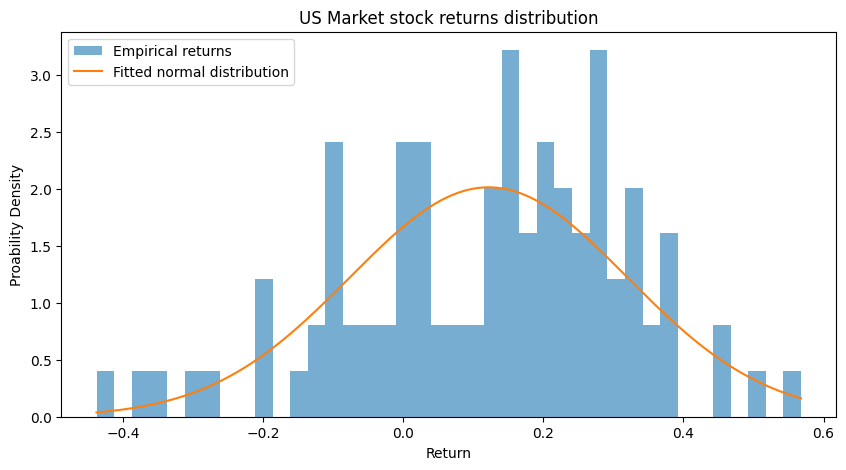

In [24]:
mean = np.mean(returns["US_Market"].dropna())
std = np.std(returns["US_Market"].dropna(), ddof=1)
risk_premium = mean - risk_free_rate

stats = {
    "Mean": mean,
    "Standard deviation": std,
    "Risk Premium": risk_premium,
    "Max": returns["US_Market"].max(),
    "Min": returns["US_Market"].min(),
}


df = pd.DataFrame(stats, index=["US_Market"])
display(df)

plot_return_distribution(
    returns["US_Market"].dropna(), "US Market stock returns distribution", compare=True
)

,Mean,Standard deviation,Risk Premium,Max,Min
T_Bills,0.033308,0.030579,0.0,0.1471,-0.0002


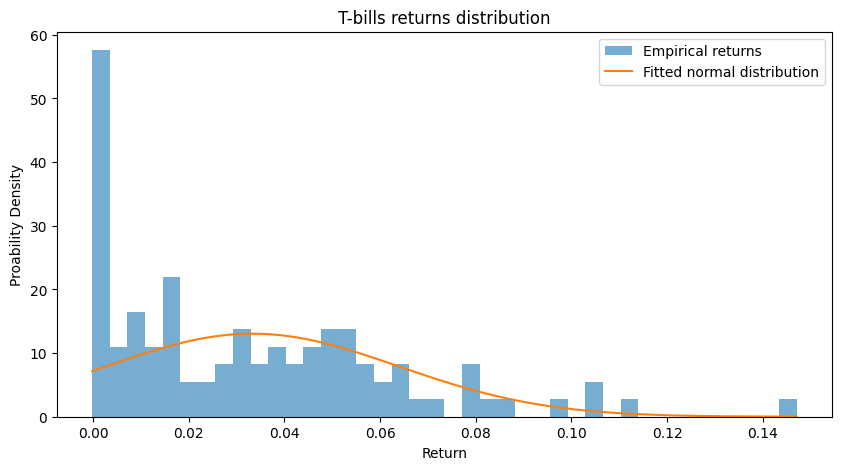

In [25]:
mean = np.mean(returns["T_Bills"].dropna())
std = np.std(returns["T_Bills"].dropna(), ddof=1)
risk_premium = mean - risk_free_rate

stats = {
    "Mean": mean,
    "Standard deviation": std,
    "Risk Premium": risk_premium,
    "Max": returns["T_Bills"].max(),
    "Min": returns["T_Bills"].min(),
}


df = pd.DataFrame(stats, index=["T_Bills"])
display(df)

plot_return_distribution(
    returns["T_Bills"].dropna(), "T-bills returns distribution", compare=True
)

# 5. Now lets use log returns instead

In [16]:
returns["log_US_Market"] = np.log1p(returns["US_Market"].dropna())
returns["log_T_Bills"] = np.log1p(returns["T_Bills"].dropna())
returns.head()

,US_Market,T_Bills,log_US_Market,log_T_Bills
Date,,,,
1927,0.3256,0.0312,0.281865,0.030723
1928,0.3912,0.0356,0.330167,0.034981
1929,-0.1483,0.0475,-0.160521,0.046406
1930,-0.2873,0.0241,-0.338695,0.023814
1931,-0.4377,0.0107,-0.575720,0.010643


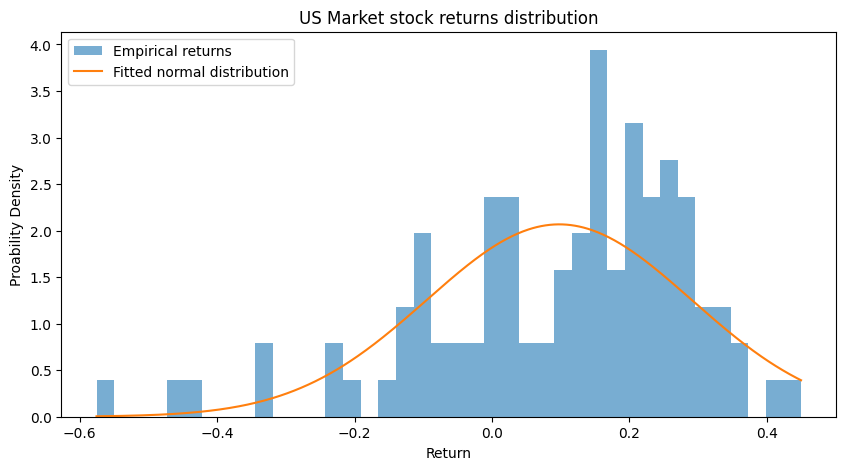

In [ ]:
plot_return_distribution(
    returns["log_US_Market"].dropna(),
    "US Market stock log returns distribution",
    compare=True,
)

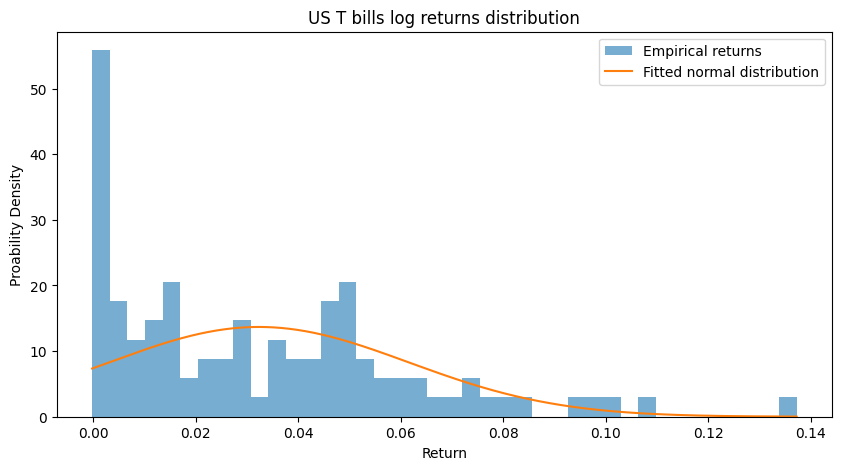

In [18]:
plot_return_distribution(
    returns["log_T_Bills"].dropna(), "US T bills log returns distribution", compare=True
)